# Task 3 — Real-World Dataset Analysis: 145 Years of Global Temperature
**YuvaIntern · Data Analyst Internship** · **Intern:** [Your Name]

## 1. Dataset selection and context
**Dataset:** NASA GISS Surface Temperature Analysis (GISTEMP v4) — *Land-Ocean Temperature Index, Global Means*.
**Source:** NASA Goddard Institute for Space Studies (file `GLB.Ts+dSST.csv`).

Each value is a **temperature anomaly in °C**: how much warmer or colder a month was compared with the 1951–1980 average. Using anomalies instead of raw temperatures lets readings from thousands of land stations and ships be combined fairly.

| Column | Meaning |
|---|---|
| `Year` | Calendar year (1880 onwards) |
| `Jan` … `Dec` | Monthly global anomaly |
| `J-D` | Annual mean, January–December |
| `D-N` | Annual mean, December of previous year – November |
| `DJF`, `MAM`, `JJA`, `SON` | Seasonal means (winter, spring, summer, autumn in the northern hemisphere) |

**Analytical objectives**
1. How much has the planet warmed since 1880?
2. Is the warming speeding up?
3. Which years, decades, months and seasons are warmest?
4. Is recent warming within the range of natural year-to-year variation?

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)
BLUE, ORANGE, AQUA, YELLOW, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948"
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

## 2. Explore the raw dataset

In [2]:
with open("data/GLB.Ts+dSST.csv") as f:
    print("First line of file:", f.readline().strip())     # a title line, not the header

raw = pd.read_csv("data/GLB.Ts+dSST.csv", skiprows=1)
print("Shape:", raw.shape)
display(raw.head())
display(raw.tail(3))

First line of file: Land-Ocean: Global Means
Shape: (147, 19)


,Year,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,J-D,D-N,DJF,MAM,JJA,SON
0,1880,-0.19,-0.25,-.09,-.16,-.10,-.21,-.18,-.10,-.14,-.23,-.22,-.19,-.17,***,***,-.12,-.17,-.20
1,1881,-0.20,-0.15,.02,.04,.07,-.19,.01,-.04,-.15,-.21,-.18,-.07,-.09,-.10,-.18,.04,-.07,-.18
2,1882,0.16,0.14,.04,-.16,-.14,-.23,-.16,-.08,-.15,-.23,-.17,-.36,-.11,-.09,.08,-.09,-.16,-.18
3,1883,-0.29,-0.36,-.12,-.18,-.18,-.07,-.08,-.14,-.22,-.11,-.24,-.12,-.18,-.20,-.34,-.16,-.10,-.19
4,1884,-0.13,-0.08,-.37,-.40,-.34,-.35,-.31,-.28,-.27,-.25,-.33,-.31,-.28,-.27,-.11,-.37,-.31,-.28


,Year,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,J-D,D-N,DJF,MAM,JJA,SON
144,2024,1.25,1.43,1.39,1.31,1.16,1.24,1.20,1.30,1.23,1.34,1.29,1.26,1.28,1.29,1.34,1.29,1.25,1.29
145,2025,1.37,1.26,1.37,1.24,1.08,1.06,1.02,1.17,1.25,1.19,1.21,1.07,1.19,1.21,1.30,1.23,1.08,1.21
146,2026,1.08,1.24,***,***,***,***,***,***,***,***,***,***,***,***,1.13,***,***,***


In [3]:
print(raw.dtypes.value_counts())
print()
text_cols = list(raw.select_dtypes(exclude="number").columns)
print(f"Columns read as text instead of numbers ({len(text_cols)}):", text_cols)

str        16
float64     2
int64       1
Name: count, dtype: int64

Columns read as text instead of numbers (16): ['Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec', 'J-D', 'D-N', 'DJF', 'MAM', 'JJA', 'SON']


Almost every numeric column was read as **text**. The cause is the placeholder `***`, which NASA uses for values that cannot be calculated.

In [4]:
marker_counts = (raw == "***").sum()
print("Cells containing '***':", int(marker_counts.sum()))
display(marker_counts[marker_counts > 0].to_frame("count_of_***"))
print("Duplicate rows:", raw.duplicated().sum(), "| Duplicate years:", raw.Year.duplicated().sum())
print("Year range:", raw.Year.min(), "-", raw.Year.max(), "| Years expected:", raw.Year.max() - raw.Year.min() + 1, "| rows:", len(raw))

Cells containing '***': 17


,count_of_***
Mar,1
Apr,1
May,1
Jun,1
Jul,1
Aug,1
Sep,1
Oct,1
Nov,1
Dec,1


Duplicate rows: 0 | Duplicate years: 0
Year range: 1880 - 2026 | Years expected: 147 | rows: 147


**Findings from exploration**
- Line 1 is a title, so the real header is on line 2 (`skiprows=1`).
- `***` marks missing values, which forced 16 of the 18 numeric columns to be read as text.
- 1880 has no `D-N`/`DJF` because December 1879 is not in the record.
- 2026 is a **partial year** (only January and February are available).
- No duplicate rows, no duplicate years and no gaps in the year sequence.

## 3. Clean and preprocess

In [5]:
df = raw.replace("***", np.nan)                       # 1. placeholder -> proper missing value
num_cols = df.columns.drop("Year")
df[num_cols] = df[num_cols].apply(pd.to_numeric)      # 2. text -> float
df["Year"] = df["Year"].astype(int)

print(df.dtypes.value_counts())
print("Missing values per row (last 3 years):")
print(df.set_index("Year").isna().sum(axis=1).tail(3))

float64    18
int64       1
Name: count, dtype: int64
Missing values per row (last 3 years):
Year
2024     0
2025     0
2026    15
dtype: int64


In [6]:
# 3. Consistency check: does the published annual mean equal the mean of the 12 months?
complete = df.dropna(subset=MONTHS).copy()
complete["J-D_check"] = complete[MONTHS].mean(axis=1)
diff = (complete["J-D"] - complete["J-D_check"]).abs()
print(f"Max difference between J-D and recalculated mean: {diff.max():.3f} °C (rounding only)")

Max difference between J-D and recalculated mean: 0.006 °C (rounding only)


In [7]:
# 4. Separate the incomplete year so it cannot bias annual statistics
partial = df[df[MONTHS].isna().any(axis=1)]
annual = df.dropna(subset=["J-D"])[["Year", "J-D", "DJF", "MAM", "JJA", "SON"]].rename(columns={"J-D": "anomaly"})
print("Excluded from annual analysis:", partial.Year.tolist())
print("Complete years kept:", len(annual), f"({annual.Year.min()}-{annual.Year.max()})")

Excluded from annual analysis: [2026]
Complete years kept: 146 (1880-2025)


In [8]:
# 5. Reshape monthly data from wide to long and build a proper date column
monthly = df.melt(id_vars="Year", value_vars=MONTHS, var_name="month", value_name="anomaly")
monthly["month_num"] = monthly["month"].map({m: i + 1 for i, m in enumerate(MONTHS)})
monthly["date"] = pd.to_datetime(dict(year=monthly.Year, month=monthly.month_num, day=1))
monthly = monthly.dropna(subset=["anomaly"]).sort_values("date").reset_index(drop=True)
print("Monthly records:", len(monthly), "| from", monthly.date.min().date(), "to", monthly.date.max().date())
display(monthly.tail(3))

Monthly records: 1754 | from 1880-01-01 to 2026-02-01


,Year,month,anomaly,month_num,date
1751,2025,Dec,1.07,12,2025-12-01
1752,2026,Jan,1.08,1,2026-01-01
1753,2026,Feb,1.24,2,2026-02-01


In [9]:
# 6. Outliers: values far from the long-term trend (residual z-score > 3)
annual["trend_30yr"] = annual["anomaly"].rolling(31, center=True, min_periods=10).mean()
annual["residual"] = annual["anomaly"] - annual["trend_30yr"]
annual["resid_z"] = stats.zscore(annual["residual"], nan_policy="omit")
monthly["trend"] = monthly["anomaly"].rolling(361, center=True, min_periods=60).mean()
monthly["resid_z"] = stats.zscore(monthly["anomaly"] - monthly["trend"])
print("Annual values with |z| > 3:")
display(annual.loc[annual.resid_z.abs() > 3, ["Year", "anomaly", "trend_30yr", "resid_z"]].round(2))
mo = monthly[monthly.resid_z.abs() > 3][["date", "anomaly", "resid_z"]]
print("Monthly values with |z| > 3:", len(mo))
display(mo.round({"anomaly": 2, "resid_z": 2}))

Annual values with |z| > 3:


,Year,anomaly,trend_30yr,resid_z
144,2024,1.28,0.89,3.42


Monthly values with |z| > 3: 11


,date,anomaly,resid_z
84,1887-01-01,-0.72,-3.23
156,1893-01-01,-0.81,-3.64
443,1916-12-01,-0.82,-3.35
719,1939-12-01,0.42,3.14
1322,1990-03-01,0.80,3.09
1633,2016-02-01,1.36,3.56
1634,2016-03-01,1.35,3.49
1724,2023-09-01,1.48,3.79
1726,2023-11-01,1.40,3.26
1729,2024-02-01,1.43,3.43


Only one year and eleven months are statistical outliers. They match known real climate events (for example the strong El Niño of 2015-16 and the record heat of 2023-24, and cold early winters in the 1880s-1910s), not recording errors, so they were **kept** and flagged rather than removed.

In [10]:
df.to_csv("data/gistemp_clean_wide.csv", index=False)
annual.to_csv("data/gistemp_annual_clean.csv", index=False)
monthly.drop(columns=["trend"]).to_csv("data/gistemp_monthly_long.csv", index=False)
print("Cleaned files saved in data/")

Cleaned files saved in data/


## 4. Exploratory data analysis
### 4.1 Descriptive statistics by era

In [11]:
annual["era"] = pd.cut(annual.Year, bins=[1879, 1940, 1980, 2025],
                       labels=["1880-1940", "1941-1980", "1981-2025"])
era_stats = annual.groupby("era", observed=True)["anomaly"].describe()[["count", "mean", "std", "min", "50%", "max"]]
display(era_stats.round(3))

,count,mean,std,min,50%,max
era,,,,,,
1880-1940,61.0,-0.241,0.128,-0.49,-0.23,0.12
1941-1980,40.0,0.003,0.112,-0.20,0.01,0.25
1981-2025,45.0,0.584,0.298,0.12,0.61,1.28


### 4.2 Warmest and coldest years

In [12]:
top10 = annual.nlargest(10, "anomaly")[["Year", "anomaly"]].reset_index(drop=True)
top10.index += 1
display(top10)
print("All 10 warmest years are after", top10.Year.min() - 1)
print("Coldest year:", int(annual.loc[annual.anomaly.idxmin(), "Year"]), f"({annual.anomaly.min():.2f} °C)")
print(f"Total change, first 30 yrs avg -> last 10 yrs avg: "
      f"{annual.anomaly.tail(10).mean() - annual.anomaly.head(30).mean():+.2f} °C")

,Year,anomaly
1,2024,1.28
2,2025,1.19
3,2023,1.17
4,2016,1.01
5,2020,1.01
6,2019,0.98
7,2017,0.91
8,2015,0.89
9,2022,0.89
10,2018,0.85


All 10 warmest years are after 2014
Coldest year: 1909 (-0.49 °C)
Total change, first 30 yrs avg -> last 10 yrs avg: +1.27 °C


### 4.3 Is warming accelerating? Trend in °C per decade

In [13]:
def trend(start, end):
    part = annual[(annual.Year >= start) & (annual.Year <= end)]
    res = stats.linregress(part.Year, part.anomaly)
    return pd.Series({"°C per decade": res.slope * 10, "R²": res.rvalue ** 2, "p-value": res.pvalue})

periods = {"1880-2025": (1880, 2025), "1880-1940": (1880, 1940), "1941-1980": (1941, 1980),
           "1981-2025": (1981, 2025), "2001-2025": (2001, 2025)}
trends = pd.DataFrame({k: trend(*v) for k, v in periods.items()}).T
display(trends.round(4))

,°C per decade,R²,p-value
1880-2025,0.0831,0.7665,0.0000
1880-1940,0.0177,0.0602,0.0566
1941-1980,0.0119,0.0156,0.4427
1981-2025,0.2126,0.8749,0.0000
2001-2025,0.2617,0.7919,0.0000


In [14]:
annual["decade"] = (annual.Year // 10) * 10
decades = annual.groupby("decade")["anomaly"].mean()
display(decades.round(3).to_frame("mean anomaly °C").T)
annual["yoy_change"] = annual["anomaly"].diff()
print(f"Typical year-to-year change (std): {annual.yoy_change.std():.3f} °C")
records = (annual["anomaly"] == annual["anomaly"].cummax()).sum() - 1
recent_records = annual[(annual.anomaly == annual.anomaly.cummax()) & (annual.Year > 1980)].Year.tolist()
print("Record-warm years since 1880:", int(records), "| since 1980:", recent_records)

decade,1880,1890,1900,1910,1920,1930,1940,1950,1960,1970,1980,1990,2000,2010,2020
mean anomaly °C,-0.214,-0.243,-0.322,-0.337,-0.242,-0.123,0.042,-0.047,-0.03,0.035,0.245,0.383,0.585,0.803,1.065


Typical year-to-year change (std): 0.112 °C
Record-warm years since 1880: 24 | since 1980: [1981, 1987, 1988, 1990, 1997, 1998, 2002, 2005, 2010, 2014, 2015, 2016, 2020, 2023, 2024]


### 4.4 Months and seasons

In [15]:
recent = df[(df.Year >= 1996) & (df.Year <= 2025)][MONTHS].mean()
early = df[(df.Year >= 1880) & (df.Year <= 1909)][MONTHS].mean()
seasonal = annual[annual.Year >= 1996][["DJF", "MAM", "JJA", "SON"]].mean()
display(pd.DataFrame({"1880-1909": early, "1996-2025": recent, "change": recent - early}).round(3).T)
display(seasonal.round(3).to_frame("1996-2025 mean").T)
hm = monthly.loc[monthly.anomaly.idxmax()]
print(f"Warmest single month on record: {hm.month} {hm.Year} ({hm.anomaly:.2f} °C)")

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
1880-1909,-0.340,-0.293,-0.260,-0.264,-0.264,-0.268,-0.220,-0.237,-0.234,-0.222,-0.254,-0.261
1996-2025,0.735,0.764,0.818,0.728,0.688,0.688,0.688,0.722,0.731,0.757,0.773,0.724
change,1.074,1.057,1.079,0.993,0.952,0.955,0.908,0.959,0.965,0.979,1.027,0.985


,DJF,MAM,JJA,SON
1996-2025 mean,0.732,0.746,0.699,0.754


Warmest single month on record: Sep 2023 (1.48 °C)


### 4.5 Correlation between seasons and with time

In [16]:
corr = annual[["Year", "anomaly", "DJF", "MAM", "JJA", "SON"]].corr().round(3)
display(corr)

,Year,anomaly,DJF,MAM,JJA,SON
Year,1.000,0.876,0.852,0.863,0.870,0.852
anomaly,0.876,1.000,0.967,0.987,0.992,0.981
DJF,0.852,0.967,1.000,0.965,0.945,0.918
MAM,0.863,0.987,0.965,1.000,0.974,0.949
JJA,0.870,0.992,0.945,0.974,1.000,0.974
SON,0.852,0.981,0.918,0.949,0.974,1.000


### 4.6 Is recent warming bigger than natural variation?
Compare 1951–1980 (the base period) with 1996–2025 using Welch's t-test.

In [17]:
base = annual[(annual.Year >= 1951) & (annual.Year <= 1980)].anomaly
last30 = annual[(annual.Year >= 1996) & (annual.Year <= 2025)].anomaly
t, p = stats.ttest_ind(last30, base, equal_var=False)
print(f"1951-1980 mean = {base.mean():.3f} (sd {base.std():.3f}) | 1996-2025 mean = {last30.mean():.3f} (sd {last30.std():.3f})")
print(f"Difference = {last30.mean() - base.mean():.2f} °C = {(last30.mean() - base.mean()) / base.std():.1f} base-period standard deviations")
print(f"Welch t = {t:.2f}, p = {p:.1e}")
print("Coldest year of 1996-2025:", f"{last30.min():.2f}", "vs warmest year of 1951-1980:", f"{base.max():.2f}")

1951-1980 mean = 0.000 (sd 0.108) | 1996-2025 mean = 0.735 (sd 0.243)
Difference = 0.74 °C = 6.8 base-period standard deviations
Welch t = 15.13, p = 3.8e-18
Coldest year of 1996-2025: 0.33 vs warmest year of 1951-1980: 0.25


## 5. Visualisations

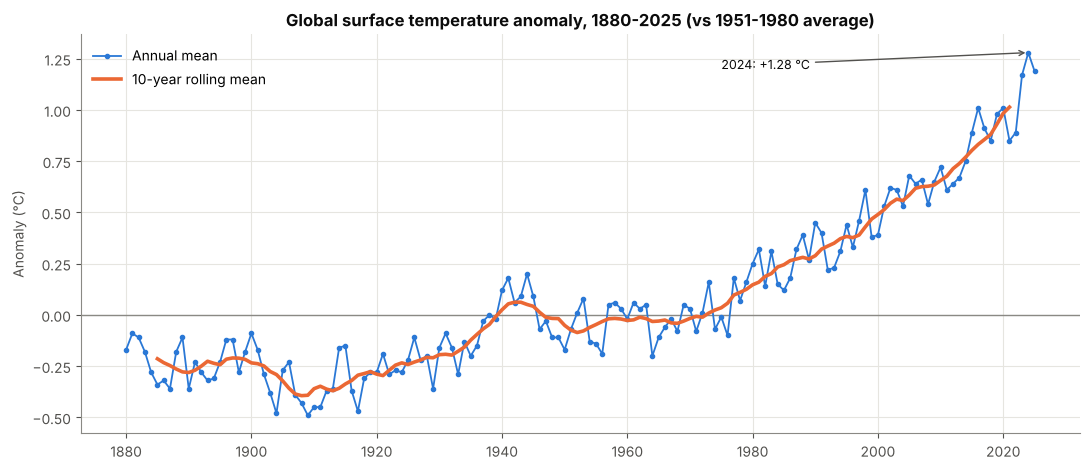

In [18]:
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.axhline(0, color="#8a8984", linewidth=1)
ax.plot(annual.Year, annual.anomaly, color=BLUE, linewidth=1.3, marker="o", markersize=3, label="Annual mean")
ax.plot(annual.Year, annual.anomaly.rolling(10, center=True).mean(), color=ORANGE, linewidth=2.6, label="10-year rolling mean")
ax.annotate(f"2024: {annual.anomaly.max():+.2f} °C", xy=(2024, annual.anomaly.max()), xytext=(1975, 1.2),
            arrowprops=dict(arrowstyle="->", color="#52514e"), fontsize=9, color="#0b0b0b")
ax.set_title("Global surface temperature anomaly, 1880-2025 (vs 1951-1980 average)")
ax.set_ylabel("Anomaly (°C)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("figures/01_line_annual_anomaly.png", dpi=150, bbox_inches="tight")

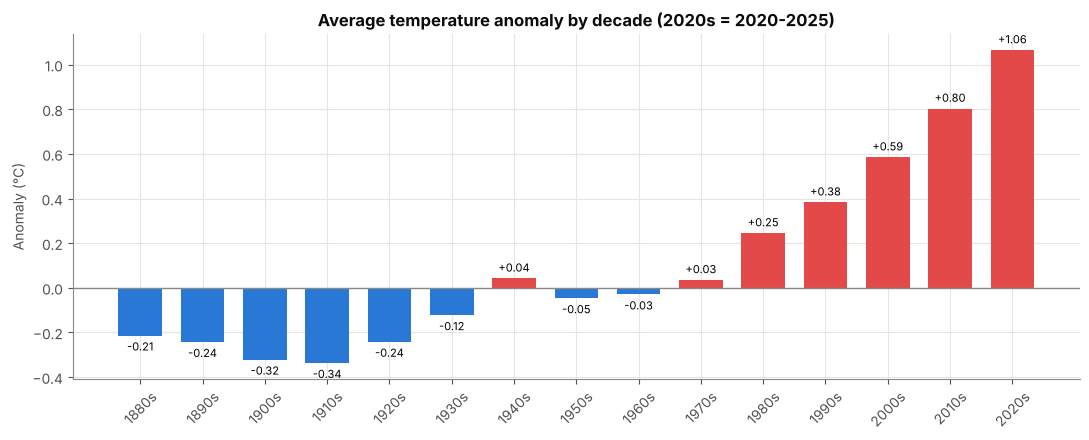

In [19]:
fig, ax = plt.subplots(figsize=(11, 4.5))
dec = decades[decades.index <= 2020]
colors = [RED if v > 0 else BLUE for v in dec.values]
bars = ax.bar(dec.index.astype(str) + "s", dec.values, color=colors, width=0.7)
ax.bar_label(bars, labels=[f"{v:+.2f}" for v in dec.values], padding=3, fontsize=8)
ax.axhline(0, color="#8a8984", linewidth=1)
ax.set_title("Average temperature anomaly by decade (2020s = 2020-2025)")
ax.set_ylabel("Anomaly (°C)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("figures/02_bar_decades.png", dpi=150, bbox_inches="tight")

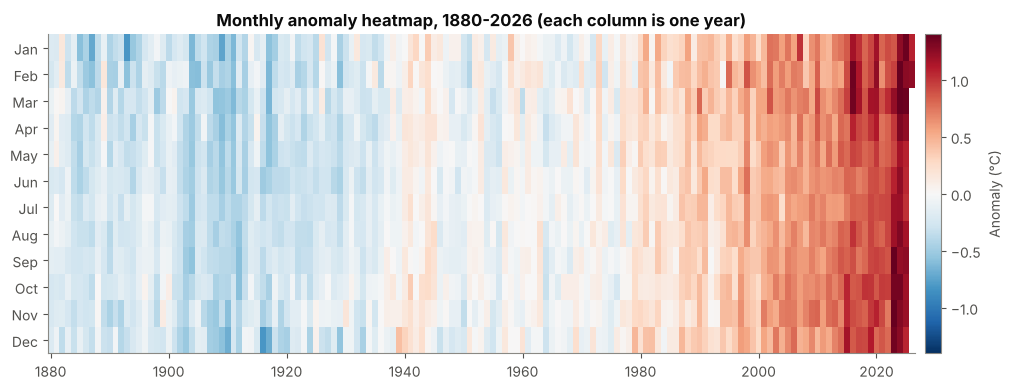

In [20]:
fig, ax = plt.subplots(figsize=(11, 4))
grid = df.set_index("Year")[MONTHS].T
im = ax.imshow(grid, aspect="auto", cmap="RdBu_r", vmin=-1.4, vmax=1.4,
               extent=[df.Year.min() - 0.5, df.Year.max() + 0.5, 11.5, -0.5])
ax.set_yticks(range(12)); ax.set_yticklabels(MONTHS)
ax.grid(False)
fig.colorbar(im, ax=ax, label="Anomaly (°C)", pad=0.01)
ax.set_title("Monthly anomaly heatmap, 1880-2026 (each column is one year)")
plt.tight_layout()
plt.savefig("figures/03_heatmap_months.png", dpi=150, bbox_inches="tight")

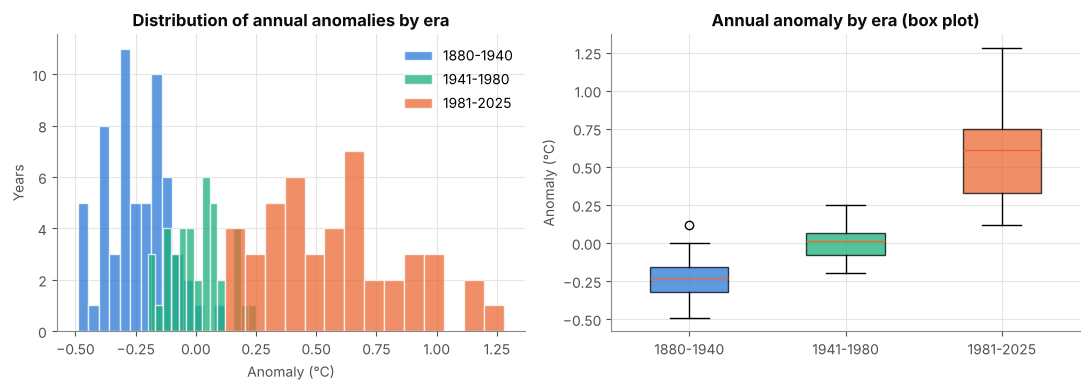

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
era_order = ["1880-1940", "1941-1980", "1981-2025"]
for era, c in zip(era_order, [BLUE, AQUA, ORANGE]):
    axes[0].hist(annual[annual.era == era].anomaly, bins=14, alpha=0.75, color=c, label=era, edgecolor="white")
axes[0].set_title("Distribution of annual anomalies by era")
axes[0].set_xlabel("Anomaly (°C)"); axes[0].set_ylabel("Years"); axes[0].legend()
bp = axes[1].boxplot([annual[annual.era == e].anomaly for e in era_order], tick_labels=era_order,
                     patch_artist=True, widths=0.5)
for patch, c in zip(bp["boxes"], [BLUE, AQUA, ORANGE]):
    patch.set_facecolor(c); patch.set_alpha(0.75)
axes[1].set_title("Annual anomaly by era (box plot)")
axes[1].set_ylabel("Anomaly (°C)")
plt.tight_layout()
plt.savefig("figures/04_hist_box_eras.png", dpi=150, bbox_inches="tight")

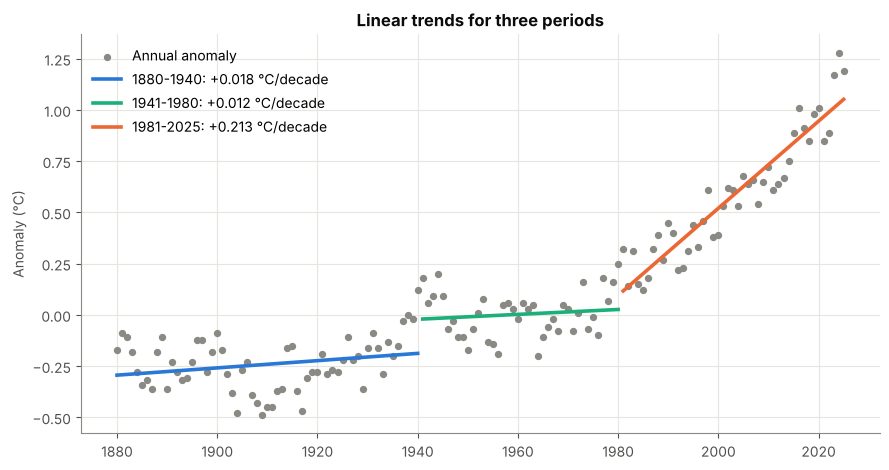

In [22]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.scatter(annual.Year, annual.anomaly, s=18, color="#8a8984", label="Annual anomaly")
for (start, end), c in [((1880, 1940), BLUE), ((1941, 1980), AQUA), ((1981, 2025), ORANGE)]:
    part = annual[(annual.Year >= start) & (annual.Year <= end)]
    res = stats.linregress(part.Year, part.anomaly)
    ax.plot(part.Year, res.intercept + res.slope * part.Year, color=c, linewidth=2.6,
            label=f"{start}-{end}: {res.slope * 10:+.3f} °C/decade")
ax.set_title("Linear trends for three periods")
ax.set_ylabel("Anomaly (°C)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("figures/05_scatter_trends.png", dpi=150, bbox_inches="tight")

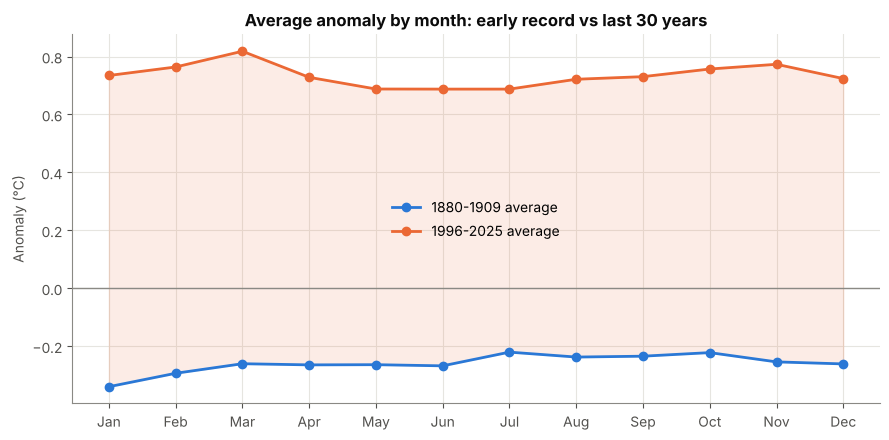

In [23]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(12)
ax.plot(x, early.values, marker="o", color=BLUE, label="1880-1909 average")
ax.plot(x, recent.values, marker="o", color=ORANGE, label="1996-2025 average")
ax.fill_between(x, early.values, recent.values, color=ORANGE, alpha=0.12)
ax.axhline(0, color="#8a8984", linewidth=1)
ax.set_xticks(x); ax.set_xticklabels(MONTHS)
ax.set_title("Average anomaly by month: early record vs last 30 years")
ax.set_ylabel("Anomaly (°C)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/06_line_months_compare.png", dpi=150, bbox_inches="tight")

## 6. Insights, conclusions and recommendations
See the accompanying report for the full interpretation. In short:
- The world has warmed by about **1.3 °C** from the 1880–1909 average to the last ten years.
- Warming is **accelerating**: since 1981 the trend is 0.21 °C per decade, about 2.5 times the long-term average of 0.08 °C per decade.
- All ten warmest years are recent, with 2024 the warmest on record.
- Every month warmed by 0.9–1.1 °C, so the change is year-round (slightly larger in January–March).
- The last 30 years are so far above the 1951–1980 range that natural year-to-year variation cannot explain them.